# Week 8 - Tasks 4 to 7: GSM8K Fine-tuning Pipeline

This notebook covers the shared GSM8K pipeline for Tasks 4-7: formatting, QLoRA fine-tuning, baselines, error analysis, and judge-based review. Keep the writeups short and focused on what the results mean.


## Colab Setup

- Use Google Colab with a T4 GPU.
- Upload the helper files from `src/` into the Colab working directory.
- If the install cell breaks, re-check the current Unsloth README before rerunning.
- Keep the API key ready for Task 7. If you change provider, keep the same judging rubric.
- Save outputs to Drive so long runs are easier to resume.


In [1]:

# Check the current Unsloth README before running if this install cell stops working.
!pip install unsloth -q
!pip install datasets evaluate rouge_score nltk trl peft litellm -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 MB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.6/915.6 MB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 108.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 91.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 105.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.

In [2]:
SEED = 42
TRAINING_SEED = 3407

import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from peft import PeftModel
from tqdm.auto import tqdm
from unsloth import FastLanguageModel

if Path("src").exists():
    sys.path.insert(0, str(Path("src").resolve()))
elif Path("../src").exists():
    sys.path.insert(0, str(Path("../src").resolve()))

from evaluation import categorize_gsm8k_error, evaluate_dataset, extract_answer, is_correct
from formatting import format_gsm8k_messages, format_training_text, manual_format_qwen3
from inference import build_eval_messages, generate_from_messages
from judging import judge_pairwise, judge_reasoning, score_rows_with_judge, summarize_judge_scores
from training import load_lora_model, report_parameter_stats, run_training_experiment
from visualization import plot_loss_curves

random.seed(SEED)
np.random.seed(SEED)
_ = torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 200)

assert torch.cuda.is_available(), "No GPU found. Switch the Colab runtime to T4 before running this notebook."
print(f"GPU:  {torch.cuda.get_device_name(0)}")
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


/usr/local/lib/python3.12/dist-packages/unsloth/__init__.py:1427: UserWarning: WARNING: Unsloth should be imported before [transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
GPU:  Tesla T4
VRAM: 15.6 GB


In [3]:
from google.colab import drive

DRIVE_MOUNT_PATH = "/content/drive"
drive.mount(DRIVE_MOUNT_PATH)


Mounted at /content/drive


## Shared Constants

These constants keep the runs consistent so the later comparisons are easier to trust.


In [4]:
MODEL_NAME = "unsloth/qwen3-0.6B"
MAX_SEQ_LENGTH_OPTIONS = [300, 512, 1024, 2048]
DEFAULT_MAX_SEQ_LENGTH = 512
DEFAULT_LORA_RANK = 8
DEFAULT_LORA_ALPHA = 16
DEFAULT_LEARNING_RATE = 2e-4
GSM8K_SYSTEM_PROMPT = (
    "Solve the following math problem step by step. "
    "Show your reasoning, then write your final answer after '####'."
)
EVAL_SYSTEM_PROMPT = "Solve step by step. Write your answer after '####'."

OUTPUT_ROOT = "/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs"
PER_DEVICE_TRAIN_BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 2
NUM_TRAIN_EPOCHS = 3
LOGGING_STEPS = 10
WARMUP_RATIO = 0.05
LR_SCHEDULER_TYPE = "cosine"
OPTIMIZER_NAME = "adamw_8bit"
EVAL_SUBSET_SIZE = 200
EVAL_MAX_NEW_TOKENS = 512
MID_TRAINING_THRESHOLD = 0.3
MID_TRAINING_MAX_NEW_TOKENS = 512
EVAL_STEPS = 100
PILOT_EVAL_STEPS = 50
CHECKPOINT_STEPS = 100
SAVE_TOTAL_LIMIT = 2
RESUME_IF_AVAILABLE = True
Path(OUTPUT_ROOT).mkdir(parents=True, exist_ok=True)

# Copy Baseline 1 from task2 after you verify it there.
BASELINE_1_ZERO_SHOT_ACCURACY = 0.50
BASELINE_1_ZERO_SHOT_PARSE_FAILURE_RATE = 0.00

MID_TRAINING_QUESTIONS = [
    "Janet has 12 apples, buys 8 more, and gives 5 away. How many apples does she have now?",
    "A runner jogs 4 miles each day for 6 days. How many miles total did the runner jog?",
    "A store sold 18 pens in the morning and 27 in the afternoon. If 10 were returned, how many pens were kept sold?",
]

GENERAL_KNOWLEDGE_QUESTIONS = [
    "What is the capital of France?",
    "What planet is known as the Red Planet?",
    "Who wrote Hamlet?",
    "What gas do plants absorb from the air?",
    "What is the largest ocean on Earth?",
    "What is 7 multiplied by 8?",
    "Which continent is Egypt in?",
    "What is the boiling point of water in Celsius?",
    "Who painted the Mona Lisa?",
    "What is the capital of Japan?",
]

print({
    "output_root": OUTPUT_ROOT,
    "per_device_train_batch_size": PER_DEVICE_TRAIN_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "num_train_epochs": NUM_TRAIN_EPOCHS,
    "logging_steps": LOGGING_STEPS,
    "warmup_ratio": WARMUP_RATIO,
    "lr_scheduler_type": LR_SCHEDULER_TYPE,
    "optimizer": OPTIMIZER_NAME,
    "eval_subset_size": EVAL_SUBSET_SIZE,
    "eval_max_new_tokens": EVAL_MAX_NEW_TOKENS,
    "mid_training_threshold": MID_TRAINING_THRESHOLD,
    "mid_training_max_new_tokens": MID_TRAINING_MAX_NEW_TOKENS,
    "eval_steps": EVAL_STEPS,
    "pilot_eval_steps": PILOT_EVAL_STEPS,
    "checkpoint_steps": CHECKPOINT_STEPS,
    "save_total_limit": SAVE_TOTAL_LIMIT,
    "resume_if_available": RESUME_IF_AVAILABLE,
})


{'output_root': '/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs', 'per_device_train_batch_size': 4, 'gradient_accumulation_steps': 2, 'num_train_epochs': 3, 'logging_steps': 10, 'warmup_ratio': 0.05, 'lr_scheduler_type': 'cosine', 'optimizer': 'adamw_8bit', 'eval_subset_size': 200, 'eval_max_new_tokens': 512, 'mid_training_threshold': 0.3, 'mid_training_max_new_tokens': 512, 'eval_steps': 100, 'pilot_eval_steps': 50, 'checkpoint_steps': 100, 'save_total_limit': 2, 'resume_if_available': True}


## Dataset Split Rules

Tasks 4-7 all use GSM8K. Make the validation split from train, and keep the official test split locked until Task 6.


In [5]:
dataset = load_dataset("openai/gsm8k", "main")
split = dataset["train"].train_test_split(test_size=0.1, seed=SEED)
train_data = split["train"]
val_data = split["test"]
test_data = dataset["test"]

print({
    "train_size": len(train_data),
    "val_size": len(val_data),
    "test_size": len(test_data),
})


README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

{'train_size': 6725, 'val_size': 748, 'test_size': 1319}


## Load the Base Model and Tokenizer

Load the tokenizer early for the formatting checks. The base model is then reused for baselines and for comparison against the fine-tuned model.


In [6]:
base_model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
    load_in_4bit=True,
    dtype=None,
)
FastLanguageModel.for_inference(base_model)

print({
    "model_name": MODEL_NAME,
    "default_max_seq_length": DEFAULT_MAX_SEQ_LENGTH,
    "load_in_4bit": True,
})


==((====))==  Unsloth 2026.7.3: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

{'model_name': 'unsloth/qwen3-0.6B', 'default_max_seq_length': 512, 'load_in_4bit': True}


# Task 4 - Dataset Formatting


## Task 4.1 - Chat Templates

Compare three training examples two ways: hand-written format and `tokenizer.apply_chat_template(...)`. The point is to confirm the model sees exactly the prompt format it expects.


In [7]:
print(tokenizer.chat_template)


{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0].role == 'system' %}
        {{- messages[0].content + '\n\n' }}
    {%- endif %}
    {{- "# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0].role == 'system' %}
        {{- '<|im_start|>system\n' + messages[0].content + '<|im_end|>\n' }}
    {%- endif %}
{%- endif %}
{%- set ns = namespace(multi_step_tool=true, last_query_index=messages|length - 1) %}
{%- for forward_message in messages %}
    {%- set index = (messages|length 

In [8]:
sample_messages = format_gsm8k_messages(train_data[0], GSM8K_SYSTEM_PROMPT)
sample_messages


[{'role': 'system',
  'content': "Solve the following math problem step by step. Show your reasoning, then write your final answer after '####'."},
 {'role': 'user',
  'content': 'A kilogram of pork costs $6 while a kilogram of chicken costs $2 less. How much will a 3-kilogram of chicken and a kilogram of pork cost?'},
 {'role': 'assistant',
  'content': 'A kilogram of chicken costs $6 - $2 = $<<6-2=4>>4.\nThree kilograms of chicken cost $4 x 3 = $<<4*3=12>>12.\nSo, a 3-kilogram of chicken and a kilogram of pork cost $12 + $6 = $18.\n#### 18'}]

In [9]:
template_checks = []
for index in range(3):
    example = train_data[index]
    manual_text = manual_format_qwen3(example, GSM8K_SYSTEM_PROMPT)
    template_text = tokenizer.apply_chat_template(
        format_gsm8k_messages(example, GSM8K_SYSTEM_PROMPT),
        tokenize=False,
        add_generation_prompt=False,
    )
    template_checks.append({
        "index": index,
        "manual_matches_template": manual_text == template_text,
        "manual_text": manual_text,
        "template_text": template_text,
    })
pd.DataFrame(template_checks)


,index,manual_matches_template,manual_text,template_text
0,0,True,"<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nA kilogram of pork costs $6 while a kilogram of chicken costs $2 less. How much will a 3-kilogram of chicken and a kilogram of pork cost?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nA kilogram of chicken costs $6 - $2 = $<<6-2=4>>4.\nThree kilograms of chicken cost $4 x 3 = $<<4*3=12>>12.\nSo, a 3-kilogram of chicken and a kilogram of pork cost $12 + $6 = $18.\n#### 18<|im_end|>\n","<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nA kilogram of pork costs $6 while a kilogram of chicken costs $2 less. How much will a 3-kilogram of chicken and a kilogram of pork cost?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nA kilogram of chicken costs $6 - $2 = $<<6-2=4>>4.\nThree kilograms of chicken cost $4 x 3 = $<<4*3=12>>12.\nSo, a 3-kilogram of chicken and a kilogram of pork cost $12 + $6 = $18.\n#### 18<|im_end|>\n"
1,1,True,"<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nSeveral birds were sitting in the branches of a crape myrtle tree. There were three times more cardinals than bluebirds, but half as many swallows as bluebirds. If there were 2 swallows, what is the total number of birds in the crape myrtle tree?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nWith half as many swallows as bluebirds, there are 2*2=<<2*2=4>>4 bluebirds.\nWith three times more cardinals than bluebirds, there are 3*4=<<3*4=12>>12 cardinals,\nIf there were 2 swallows, then the total number of birds in the crape myrtle tree is 2+4+12=<<2+4+12=18>>18 birds.\n#### 18<|im_end|>\n","<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nSeveral birds were sitting in the branches of a crape myrtle tree. There were three times more cardinals than bluebirds, but half as many swallows as bluebirds. If there were 2 swallows, what is the total number of birds in the crape myrtle tree?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nWith half as many swallows as bluebirds, there are 2*2=<<2*2=4>>4 bluebirds.\nWith three times more cardinals than bluebirds, there are 3*4=<<3*4=12>>12 cardinals,\nIf there were 2 swallows, then the total number of birds in the crape myrtle tree is 2+4+12=<<2+4+12=18>>18 birds.\n#### 18<|im_end|>\n"
2,2,True,"<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nKenny played 10 hours of basketball last week. He ran for twice as long as he played basketball, and he practiced on the trumpet for twice as long as he ran. How many hours did Kenny practice on the trumpet last week?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nKenny ran for 10*2=<<10*2=20>>20 hours.\nKenny practiced the trumpet for 20*2=<<20*2=40>>40 hours.\n#### 40<|im_end|>\n","<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nKenny played 10 hours of basketball last week. He ran for twice as long as he played basketball, and he practiced on the trumpet for twice as long as he ran. How many hours did Kenny practice on the trumpet last week?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nKenny ran for 10*2=<<10*2=20>>20 hours.\nKenny practiced the trumpet for 20*2=<<20*2=40>>40 hours.\n#### 40<|im_end|>\n"


### Task 4.1 Findings

All three manual strings matched `tokenizer.apply_chat_template(...)` exactly for the three checked examples. That validates the Qwen3 training format, including the role tags and the empty `<think>` scaffold before the answer.

If the template were wrong, the loss could still fall because the model would learn a consistent but incorrect token pattern. The failure would show up at inference time, where mismatched role boundaries make formatting and behavior unstable.


## Task 4.2 - Loss Masking

Only assistant-response tokens should contribute to the supervised loss. This check shows where the labels start and how much of the sequence is actually training the model.


In [10]:
mask_example = train_data[0]
mask_messages = format_gsm8k_messages(mask_example, GSM8K_SYSTEM_PROMPT)
mask_text = tokenizer.apply_chat_template(
    mask_messages,
    tokenize=False,
    add_generation_prompt=False,
)
tokenized = tokenizer(mask_text, return_tensors="pt", add_special_tokens=False)
input_ids = tokenized["input_ids"][0]
labels = input_ids.clone()

assistant_prefix = "<|im_start|>assistant\n<think>\n\n</think>\n\n"
assistant_start = mask_text.index(assistant_prefix) + len(assistant_prefix)
assistant_token_start = len(tokenizer(mask_text[:assistant_start], add_special_tokens=False)["input_ids"])
labels[:assistant_token_start] = -100

token_table = pd.DataFrame({
    "token_id": input_ids.tolist(),
    "token": tokenizer.convert_ids_to_tokens(input_ids.tolist()),
    "label": labels.tolist(),
})
token_table.head(80)


,token_id,token,label
0,151644,<|im_start|>,-100
1,8948,system,-100
2,198,Ċ,-100
3,50,S,-100
4,3948,olve,-100
5,279,Ġthe,-100
6,2701,Ġfollowing,-100
7,6888,Ġmath,-100
8,3491,Ġproblem,-100
9,3019,Ġstep,-100


In [11]:
loss_fraction = float((labels != -100).sum().item() / len(labels))
print(f"Assistant-response token fraction: {loss_fraction:.4f}")


Assistant-response token fraction: 0.5032


### Task 4.2 Findings

The masking check shows that 50.32% of tokens in this example contribute to loss. Labels switch from `-100` to trainable tokens immediately after `<|im_start|>assistant\n<think>\n\n</think>\n\n`, so the system prompt, user question, and assistant prefix are treated as context rather than targets.

That is the behavior we want: the model should condition on the prompt structure, not be trained to copy it. The assistant section starts at the expected Qwen3 delimiter for this template.


## Task 4.3 - Padding and EOS

Check whether padding and EOS are the same token, because that can affect batched training behavior.


In [12]:
print(f"pad_token: {tokenizer.pad_token!r}")
print(f"eos_token: {tokenizer.eos_token!r}")
print(f"Same?      {tokenizer.pad_token == tokenizer.eos_token}")


pad_token: '<|vision_pad|>'
eos_token: '<|im_end|>'
Same?      False


### Task 4.3 Findings

`pad_token` is `<|vision_pad|>` and `eos_token` is `<|im_end|>`, so they are not the same token in this setup. That avoids the usual EOS-as-padding ambiguity during batching.

Because the tokens differ, padding does not look like a real stop token here. Regular attention and loss masking are still what keep padded positions from affecting training.


## Task 4.4 - Length Distribution

Plot the training-set token lengths, then compare truncation at 512, 1024, and 2048 before choosing the final context length.


In [13]:
train_texts = [format_training_text(example, tokenizer, GSM8K_SYSTEM_PROMPT) for example in train_data]
train_lengths = [len(tokenizer(text, add_special_tokens=False)["input_ids"]) for text in tqdm(train_texts)]
length_frame = pd.DataFrame({"length": train_lengths})
length_frame.describe()


  0%|          | 0/6725 [00:00<?, ?it/s]

,length
count,6725.000000
mean,223.403271
std,67.741291
min,106.000000
25%,173.000000
50%,210.000000
75%,261.000000
max,578.000000


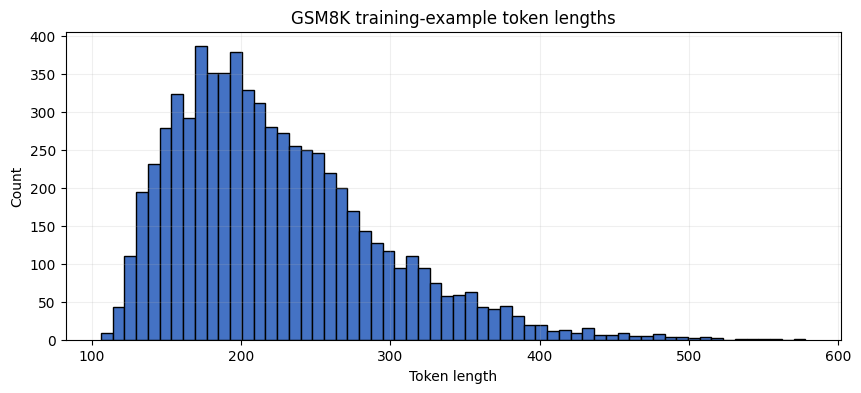

In [14]:
plt.figure(figsize=(10, 4))
plt.hist(train_lengths, bins=60, color="#4472c4", edgecolor="black")
plt.title("GSM8K training-example token lengths")
plt.xlabel("Token length")
plt.ylabel("Count")
plt.grid(alpha=0.2)
plt.show()


In [15]:
truncation_rows = []
for limit in MAX_SEQ_LENGTH_OPTIONS:
    truncation_rate = float(np.mean(np.array(train_lengths) > limit))
    truncation_rows.append({
        "max_seq_length": limit,
        "truncation_rate": truncation_rate,
    })
truncation_table = pd.DataFrame(truncation_rows)
truncation_table


,max_seq_length,truncation_rate
0,300,0.130558
1,512,0.001041
2,1024,0.000000
3,2048,0.000000


### Task 4.4 Findings

The training examples are short for this model: mean length is 223 tokens and the maximum is 578. The truncation table shows 0.10% truncation at 512 tokens and 0% truncation at 1024 and 2048, so the notebook's choice of `max_seq_length = 512` is a reasonable T4-friendly default.

That setting keeps memory and training time down while still covering essentially the whole GSM8K training set. Because truncation is far below 5%, there was no need to raise the limit or filter long samples for training.


# Task 5 - Fine-tuning and Ablations


## Task 5.1 - Load with QLoRA

Load the 4-bit base model, attach LoRA adapters, then report total params, trainable params, trainable fraction, and VRAM.


In [16]:
formatted_train = train_data.map(lambda ex: {"text": format_training_text(ex, tokenizer, GSM8K_SYSTEM_PROMPT)})
formatted_val = val_data.map(lambda ex: {"text": format_training_text(ex, tokenizer, GSM8K_SYSTEM_PROMPT)})
formatted_test = test_data.map(lambda ex: {"text": format_training_text(ex, tokenizer, GSM8K_SYSTEM_PROMPT)})


Map:   0%|          | 0/6725 [00:00<?, ? examples/s]

Map:   0%|          | 0/748 [00:00<?, ? examples/s]

Map:   0%|          | 0/1319 [00:00<?, ? examples/s]

In [ ]:
formatted_train['question'][0],formatted_train['answer'][0],formatted_train['text'][0]

('A kilogram of pork costs $6 while a kilogram of chicken costs $2 less. How much will a 3-kilogram of chicken and a kilogram of pork cost?',
 'A kilogram of chicken costs $6 - $2 = $<<6-2=4>>4.\nThree kilograms of chicken cost $4 x 3 = $<<4*3=12>>12.\nSo, a 3-kilogram of chicken and a kilogram of pork cost $12 + $6 = $18.\n#### 18',
 "<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nA kilogram of pork costs $6 while a kilogram of chicken costs $2 less. How much will a 3-kilogram of chicken and a kilogram of pork cost?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nA kilogram of chicken costs $6 - $2 = $<<6-2=4>>4.\nThree kilograms of chicken cost $4 x 3 = $<<4*3=12>>12.\nSo, a 3-kilogram of chicken and a kilogram of pork cost $12 + $6 = $18.\n#### 18<|im_end|>\n")

In [17]:
STANDARD_TARGET_MODULES = [
    "q_proj", "k_proj", "v_proj", "o_proj",
    "gate_proj", "up_proj", "down_proj",
]

standard_model, standard_tokenizer = load_lora_model(
    model_name=MODEL_NAME,
    rank=DEFAULT_LORA_RANK,
    alpha=DEFAULT_LORA_ALPHA,
    target_modules=STANDARD_TARGET_MODULES,
    max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
    random_state=TRAINING_SEED,
)

==((====))==  Unsloth 2026.7.3: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Unsloth 2026.7.3 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


In [ ]:
standard_param_report = report_parameter_stats(standard_model)

{'total_params': 393478144, 'trainable_params': 5046272, 'trainable_fraction_pct': 1.2824783477681545, 'vram_allocated_gb': 1.255806976}


## Task 5.2 - Training Run

Run one standard training job before the ablations. Focus the notes on loss behavior, format learning, and obvious reasoning mistakes.


### Pilot Training Run on 10% of the Data

Use the pilot only as a quick sanity check before the full run. It should tell you if the setup is working, not replace the real experiment.


In [ ]:
PILOT_FRACTION = 0.10
pilot_train_size = max(1, int(len(formatted_train) * PILOT_FRACTION))
pilot_val_size = max(1, int(len(formatted_val) * PILOT_FRACTION))

pilot_train = formatted_train.select(range(pilot_train_size))
pilot_val = formatted_val.select(range(pilot_val_size))
pilot_val_examples = val_data.select(range(pilot_val_size))

print({
    "pilot_fraction": PILOT_FRACTION,
    "pilot_train_size": len(pilot_train),
    "pilot_val_size": len(pilot_val),
})


{'pilot_fraction': 0.1, 'pilot_train_size': 672, 'pilot_val_size': 74}


In [ ]:
pilot_val['question'][0],pilot_val['answer'][0],pilot_val['text'][0]

('Mimi picked up 2 dozen seashells on the beach.  Kyle found twice as many shells as Mimi and put them in his pocket. Leigh grabbed one-third of the shells that Kyle found.  How many seashells did Leigh have?',
 'Mimi has 2 x 12 = <<2*12=24>>24 sea shells.\nKyle has 24 x 2 = <<24*2=48>>48 sea shells.\nLeigh has 48 / 3 = <<48/3=16>>16 sea shells.\n#### 16',
 "<|im_start|>system\nSolve the following math problem step by step. Show your reasoning, then write your final answer after '####'.<|im_end|>\n<|im_start|>user\nMimi picked up 2 dozen seashells on the beach.  Kyle found twice as many shells as Mimi and put them in his pocket. Leigh grabbed one-third of the shells that Kyle found.  How many seashells did Leigh have?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nMimi has 2 x 12 = <<2*12=24>>24 sea shells.\nKyle has 24 x 2 = <<24*2=48>>48 sea shells.\nLeigh has 48 / 3 = <<48/3=16>>16 sea shells.\n#### 16<|im_end|>\n")

In [ ]:
pilot_val_examples

Dataset({
    features: ['question', 'answer'],
    num_rows: 74
})

In [ ]:
pilot_val_examples['question'][0],pilot_val_examples['answer'][0]

('Mimi picked up 2 dozen seashells on the beach.  Kyle found twice as many shells as Mimi and put them in his pocket. Leigh grabbed one-third of the shells that Kyle found.  How many seashells did Leigh have?',
 'Mimi has 2 x 12 = <<2*12=24>>24 sea shells.\nKyle has 24 x 2 = <<24*2=48>>48 sea shells.\nLeigh has 48 / 3 = <<48/3=16>>16 sea shells.\n#### 16')

In [ ]:
pilot_trainer, pilot_run = run_training_experiment(
    run_name="pilot_r8_10pct",
    model_name=MODEL_NAME,
    rank=DEFAULT_LORA_RANK,
    alpha=DEFAULT_LORA_ALPHA,
    learning_rate=DEFAULT_LEARNING_RATE,
    target_modules=STANDARD_TARGET_MODULES,
    max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
    training_seed=TRAINING_SEED,
    mid_training_questions=MID_TRAINING_QUESTIONS,
    system_prompt=EVAL_SYSTEM_PROMPT,
    train_dataset=pilot_train,
    eval_dataset=pilot_val,
    eval_examples=pilot_val_examples,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    logging_steps=LOGGING_STEPS,
    eval_subset_size=EVAL_SUBSET_SIZE,
    mid_training_threshold=MID_TRAINING_THRESHOLD,
    mid_training_max_new_tokens=MID_TRAINING_MAX_NEW_TOKENS,
    eval_max_new_tokens=EVAL_MAX_NEW_TOKENS,
    output_root=OUTPUT_ROOT,
    eval_steps=PILOT_EVAL_STEPS,
    save_steps=CHECKPOINT_STEPS,
    save_total_limit=SAVE_TOTAL_LIMIT,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    optim=OPTIMIZER_NAME,
    resume_if_available=RESUME_IF_AVAILABLE,
)
pilot_run_summary = {
    key: value for key, value in pilot_run.items()
    if key not in {"history", "mid_training_samples", "target_modules", "adapter_path"}
}
pilot_run_summary


==((====))==  Unsloth 2026.7.1: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/672 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/74 [00:00<?, ? examples/s]

...

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 672 | Num Epochs = 3 | Total steps = 252
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 5,046,272 of 601,096,192 (0.84% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


Step,Training Loss,Validation Loss
50,0.569278,0.498853
100,0.504172,0.481066
150,0.480405,0.468216
200,0.395887,0.467775
250,0.387138,0.467856
252,0.387138,0.467859


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:172: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API 

{'run': 'pilot_r8_10pct',
 'model': 'unsloth/qwen3-0.6B',
 'rank': 8,
 'alpha': 16,
 'learning_rate': 0.0002,
 'epochs': 3,
 'train_loss': 0.38713822364807127,
 'val_loss': 0.46785926818847656,
 'gsm8k_accuracy': 0.5,
 'parse_failure_rate': 0.12162162162162163,
 'peak_vram_gb': 5.441972736,
 'time_minutes': 4.352433248360952,
 'per_device_train_batch_size': 4,
 'gradient_accumulation_steps': 2,
 'logging_steps': 10,
 'eval_steps': 50,
 'save_steps': 100,
 'save_total_limit': 2,
 'warmup_ratio': 0.05,
 'lr_scheduler_type': 'cosine',
 'optim': 'adamw_8bit',
 'eval_subset_size': 200,
 'mid_training_threshold': 0.3,
 'mid_training_max_new_tokens': 512,
 'eval_max_new_tokens': 512,
 'run_dir': '/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/pilot_r8_10pct'}

In [ ]:
pilot_run_summary

{'run': 'pilot_r8_10pct',
 'model': 'unsloth/qwen3-0.6B',
 'rank': 8,
 'alpha': 16,
 'learning_rate': 0.0002,
 'epochs': 3,
 'train_loss': 0.38713822364807127,
 'val_loss': 0.46785926818847656,
 'gsm8k_accuracy': 0.5,
 'parse_failure_rate': 0.12162162162162163,
 'peak_vram_gb': 5.441972736,
 'time_minutes': 4.352433248360952,
 'per_device_train_batch_size': 4,
 'gradient_accumulation_steps': 2,
 'logging_steps': 10,
 'eval_steps': 50,
 'save_steps': 100,
 'save_total_limit': 2,
 'warmup_ratio': 0.05,
 'lr_scheduler_type': 'cosine',
 'optim': 'adamw_8bit',
 'eval_subset_size': 200,
 'mid_training_threshold': 0.3,
 'mid_training_max_new_tokens': 512,
 'eval_max_new_tokens': 512,
 'run_dir': '/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/pilot_r8_10pct'}

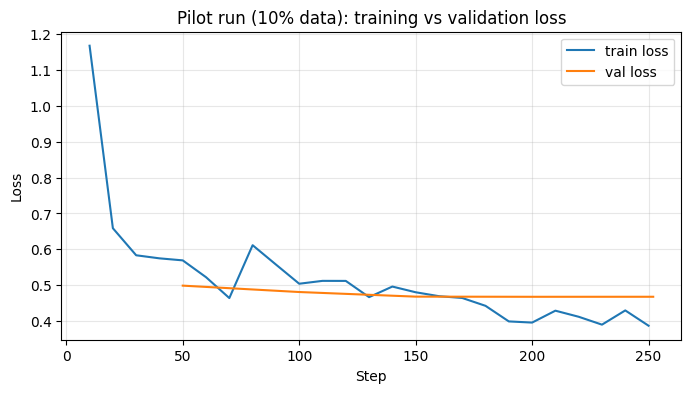

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
12,0.512153,0.839135,1.304012e-04,1.309524,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,0.512038,0.928417,1.176524e-04,1.428571,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,0.466810,0.842518,1.045990e-04,1.547619,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,0.496300,0.822559,9.146631e-05,1.666667,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,0.480405,0.913251,7.848082e-05,1.785714,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,NaN,NaN,NaN,1.785714,150,0.468216,2.6723,27.691,7.110,NaN,NaN,NaN,NaN,NaN
18,0.469469,0.782939,6.586662e-05,1.904762,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19,0.464469,0.814201,5.384133e-05,2.023810,170,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,0.442565,0.883936,4.261245e-05,2.142857,180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21,0.399157,0.845399,3.237371e-05,2.261905,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
pilot_history = plot_loss_curves(pilot_run["history"], "Pilot run (10% data): training vs validation loss")
pilot_history.tail(20)


### Standard Training Run

This is the main Task 5.2 run. Use it for the train-vs-val loss plot and for the mid-training sample check.


In [18]:
standard_trainer, standard_run = run_training_experiment(
    run_name="rank_8_2",
    model_name=MODEL_NAME,
    rank=DEFAULT_LORA_RANK,
    alpha=DEFAULT_LORA_ALPHA,
    learning_rate=DEFAULT_LEARNING_RATE,
    target_modules=STANDARD_TARGET_MODULES,
    max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
    training_seed=TRAINING_SEED,
    mid_training_questions=MID_TRAINING_QUESTIONS,
    system_prompt=EVAL_SYSTEM_PROMPT,
    train_dataset=formatted_train,
    eval_dataset=formatted_val,
    eval_examples=val_data,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    logging_steps=LOGGING_STEPS,
    eval_subset_size=EVAL_SUBSET_SIZE,
    mid_training_threshold=MID_TRAINING_THRESHOLD,
    mid_training_max_new_tokens=MID_TRAINING_MAX_NEW_TOKENS,
    eval_max_new_tokens=EVAL_MAX_NEW_TOKENS,
    output_root=OUTPUT_ROOT,
    eval_steps=EVAL_STEPS,
    save_steps=CHECKPOINT_STEPS,
    save_total_limit=SAVE_TOTAL_LIMIT,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    optim=OPTIMIZER_NAME,
    resume_if_available=RESUME_IF_AVAILABLE,
)
standard_run_summary = {
    key: value for key, value in standard_run.items()
    if key not in {"history", "mid_training_samples", "target_modules", "adapter_path"}
}


==((====))==  Unsloth 2026.7.3: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/6725 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/748 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/748 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 6,725 | Num Epochs = 3 | Total steps = 2,523
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 5,046,272 of 601,096,192 (0.84% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
100,0.503737,0.506870
200,0.513773,0.479438
300,0.487911,0.461291
400,0.457932,0.447997
500,0.482544,0.442527
600,0.452377,0.438122
700,0.504049,0.432628
800,0.470475,0.431453
900,0.407835,0.432528
1000,0.435431,0.431619


/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:172: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API 

In [19]:
standard_run_summary

{'run': 'rank_8_2',
 'model': 'unsloth/qwen3-0.6B',
 'rank': 8,
 'alpha': 16,
 'learning_rate': 0.0002,
 'epochs': 3,
 'train_loss': 0.3403367042541504,
 'val_loss': 0.42181211709976196,
 'gsm8k_accuracy': 0.115,
 'parse_failure_rate': 0.015,
 'peak_vram_gb': 5.668348416,
 'time_minutes': 42.964741015434264,
 'per_device_train_batch_size': 4,
 'gradient_accumulation_steps': 2,
 'logging_steps': 10,
 'eval_steps': 100,
 'save_steps': 100,
 'save_total_limit': 2,
 'warmup_ratio': 0.05,
 'lr_scheduler_type': 'cosine',
 'optim': 'adamw_8bit',
 'eval_subset_size': 200,
 'mid_training_threshold': 0.3,
 'mid_training_max_new_tokens': 512,
 'eval_max_new_tokens': 512,
 'run_dir': '/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_8_2'}

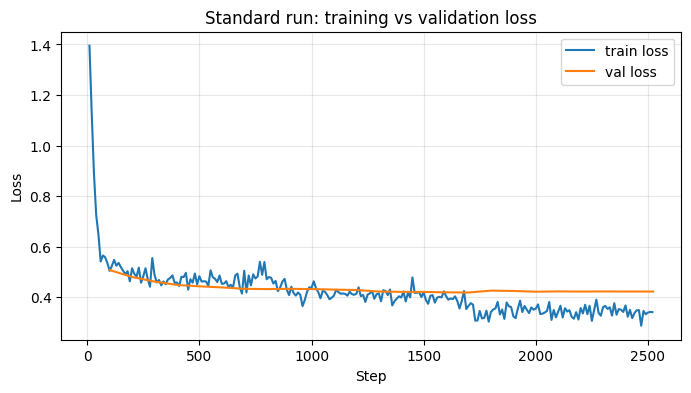

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
259,0.352482,1.007664,2.031709e-06,2.818074,2370,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
260,0.349634,0.867008,1.777176e-06,2.829964,2380,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
261,0.340966,0.739291,1.539530e-06,2.841855,2390,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,0.366776,0.748535,1.318811e-06,2.853746,2400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
263,NaN,NaN,NaN,2.853746,2400,0.421848,25.9527,28.822,7.205,NaN,NaN,NaN,NaN,NaN
264,0.322135,0.791699,1.115057e-06,2.865636,2410,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
265,0.349282,0.692547,9.283029e-07,2.877527,2420,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
266,0.316279,0.823833,7.585810e-07,2.889417,2430,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
267,0.336547,0.893267,6.059205e-07,2.901308,2440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
268,0.347587,0.801855,4.703475e-07,2.913199,2450,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
standard_history = plot_loss_curves(standard_run["history"], "Standard run: training vs validation loss")
standard_history.tail(20)


In [21]:
mid_train_df=pd.DataFrame(standard_run["mid_training_samples"])


In [22]:
mid_train_df

,global_step,question,response
0,757,"Janet has 12 apples, buys 8 more, and gives 5 away. How many apples does she have now?",<think>\nShe has 12+8=<<12+8=20>>20 apples\nShe has 20-5=<<20-5=15>>15 apples now.\n#### 15
1,757,A runner jogs 4 miles each day for 6 days. How many miles total did the runner jog?,<think>\nThe runner jogged 4 miles x 6 days = <<4*6=24>>24 miles.\n#### 24
2,757,"A store sold 18 pens in the morning and 27 in the afternoon. If 10 were returned, how many pens were kept sold?",<think>\nThe total number of pens sold is 18 + 27 = <<18+27=45>>45 pens.\nThe number of pens kept sold is 45 - 10 = <<45-10=35>>35 pens.\n#### 35


### Task 5.2 Findings

The logged summaries suggest stable optimization rather than divergence: the pilot run reached train/validation loss of 0.387/0.468, and the standard `rank_8` run logged 0.342/0.421. Validation loss stays above training loss but remains close, which looks more like ordinary generalization gap than obvious overfitting.

The midpoint probe samples are stronger than the final `rank_8` validation accuracy might suggest. By step 757, all three probe questions use the expected step-by-step format and end with `####`, and the saved probe answers for the apples, running, and pen-count questions are all correct. That suggests the model learned the answer format and simple arithmetic pattern early, while the later weaknesses come more from generalization quality than from a total failure to learn the task structure.


## Task 5.3 - Rank Ablation

Train at least `r = 4, 8, 16` with everything else fixed. Compare the runs using validation loss and validation exact-match before touching the locked test set.


In [ ]:
RANKS_TO_RUN = [4, 8, 16]  # add 32 if time permits
rank_runs = []
for rank in RANKS_TO_RUN:
    _, run_result = run_training_experiment(
        run_name=f"rank_{rank}",
        model_name=MODEL_NAME,
        rank=rank,
        alpha=DEFAULT_LORA_ALPHA,
        learning_rate=DEFAULT_LEARNING_RATE,
        target_modules=STANDARD_TARGET_MODULES,
        max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
        training_seed=TRAINING_SEED,
        mid_training_questions=MID_TRAINING_QUESTIONS,
        system_prompt=EVAL_SYSTEM_PROMPT,
        train_dataset=formatted_train,
        eval_dataset=formatted_val,
        eval_examples=val_data,
        per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        num_train_epochs=NUM_TRAIN_EPOCHS,
        logging_steps=LOGGING_STEPS,
        eval_subset_size=EVAL_SUBSET_SIZE,
        mid_training_threshold=MID_TRAINING_THRESHOLD,
        mid_training_max_new_tokens=MID_TRAINING_MAX_NEW_TOKENS,
        eval_max_new_tokens=EVAL_MAX_NEW_TOKENS,
        output_root=OUTPUT_ROOT,
        eval_steps=EVAL_STEPS,
        save_steps=CHECKPOINT_STEPS,
        save_total_limit=SAVE_TOTAL_LIMIT,
        warmup_ratio=WARMUP_RATIO,
        lr_scheduler_type=LR_SCHEDULER_TYPE,
        optim=OPTIMIZER_NAME,
        resume_if_available=RESUME_IF_AVAILABLE,
    )
    rank_runs.append(run_result)

rank_results = pd.DataFrame([
    {key: value for key, value in run.items() if key not in {"history", "mid_training_samples", "target_modules", "adapter_path"}}
    for run in rank_runs
])

==((====))==  Unsloth 2026.7.1: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/6725 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/748 [00:00<?, ? examples/s]

...

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


{'resume_from_checkpoint': '/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_16/checkpoint-2523'}


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 6,725 | Num Epochs = 3 | Total steps = 2,523
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 10,092,544 of 606,142,464 (1.67% trained)


Step,Training Loss,Validation Loss


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_16/adapter/tokenizer_config.json.
Both `max_new_tokens` (=512) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in

In [ ]:
rank_results

,run,model,rank,alpha,learning_rate,epochs,train_loss,val_loss,gsm8k_accuracy,parse_failure_rate,...,save_steps,save_total_limit,warmup_ratio,lr_scheduler_type,optim,eval_subset_size,mid_training_threshold,mid_training_max_new_tokens,eval_max_new_tokens,run_dir
0,rank_4,unsloth/qwen3-0.6B,4,16,0.0002,3,0.343957,0.422618,0.355,0.035,...,100,2,0.05,cosine,adamw_8bit,200,0.3,512,512,/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_4
1,rank_8,unsloth/qwen3-0.6B,8,16,0.0002,3,0.341693,0.421279,0.165,0.005,...,100,2,0.05,cosine,adamw_8bit,200,0.3,512,512,/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_8
2,rank_16,unsloth/qwen3-0.6B,16,16,0.0002,3,0.341123,0.419591,0.505,0.010,...,100,2,0.05,cosine,adamw_8bit,200,0.3,512,512,/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_16


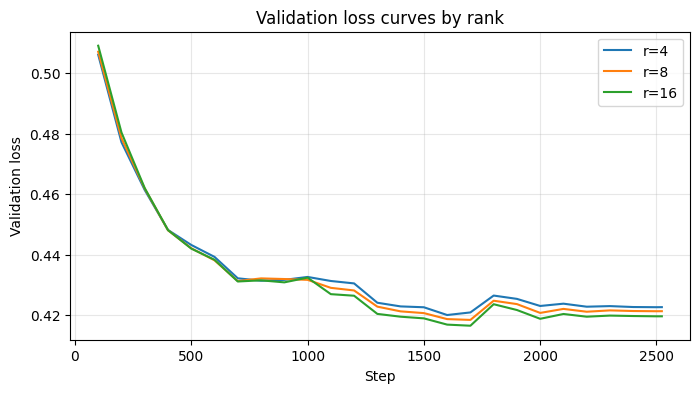

In [ ]:
plt.figure(figsize=(8, 4))
for run in rank_runs:
    history = run["history"]
    eval_curve = history.loc[history["eval_loss"].notna(), ["step", "eval_loss"]]
    if not eval_curve.empty:
        plt.plot(eval_curve["step"], eval_curve["eval_loss"], label=f"r={run['rank']}")
plt.title("Validation loss curves by rank")
plt.xlabel("Step")
plt.ylabel("Validation loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


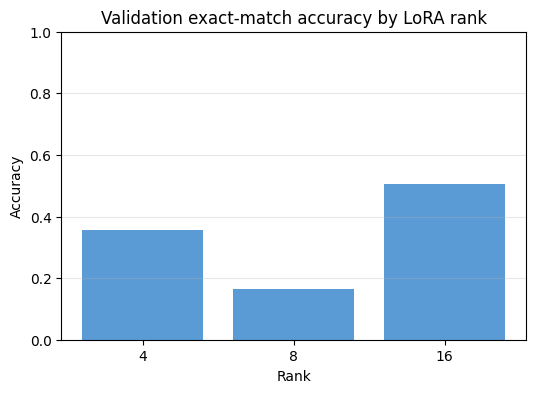

In [ ]:
plt.figure(figsize=(6, 4))
plt.bar(rank_results["rank"].astype(str), rank_results["gsm8k_accuracy"], color="#5b9bd5")
plt.title("Validation exact-match accuracy by LoRA rank")
plt.xlabel("Rank")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()


### Task 5.3 Findings

Higher rank was not monotonic across these runs: `r=8` underperformed both `r=4` and `r=16` on exact match. On the logged 200-example validation subset, `r=16` is best with the lowest validation loss (0.4196) and the highest accuracy (0.505), while `r=8` drops to 0.165 accuracy despite a very similar loss value.

Within this range, gains had not clearly flattened by `r=16`. That suggests the GSM8K adaptation needed more capacity than the smaller ranks provided, likely because the adapter had to shape both answer formatting and multi-step computation behavior rather than just memorize shallow output patterns.


## Task 5.4 - One Additional Ablation

After picking the best rank, change one thing only: learning rate, alpha, or target modules. Keep the conclusion short and practical.


In [ ]:
ADDITIONAL_ABLATION = {
    "type": "alpha",  # choose one of: "learning_rate", "alpha", "target_modules"
    "values": [4, 8, 16],
}
BEST_RANK_FROM_TASK_53 = 16
BEST_ALPHA_FROM_TASK_53 = 16
BEST_TARGET_MODULES_FROM_TASK_53 = STANDARD_TARGET_MODULES


In [ ]:
additional_runs = []
for value in ADDITIONAL_ABLATION["values"]:
    if ADDITIONAL_ABLATION["type"] == "learning_rate":
        rank = BEST_RANK_FROM_TASK_53
        alpha = BEST_ALPHA_FROM_TASK_53
        learning_rate = value
        target_modules = BEST_TARGET_MODULES_FROM_TASK_53
        run_name = f"lr_{value}"
    elif ADDITIONAL_ABLATION["type"] == "alpha":
        rank = BEST_RANK_FROM_TASK_53
        alpha = value
        learning_rate = DEFAULT_LEARNING_RATE
        target_modules = BEST_TARGET_MODULES_FROM_TASK_53
        run_name = f"alpha_{value}"
    else:
        rank = BEST_RANK_FROM_TASK_53
        alpha = BEST_ALPHA_FROM_TASK_53
        learning_rate = DEFAULT_LEARNING_RATE
        target_modules = ["q_proj", "k_proj", "v_proj", "o_proj"] if value == "attention_only" else STANDARD_TARGET_MODULES
        run_name = f"modules_{value}"

    _, run_result = run_training_experiment(
        run_name=run_name,
        model_name=MODEL_NAME,
        rank=rank,
        alpha=alpha,
        learning_rate=learning_rate,
        target_modules=target_modules,
        max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
        training_seed=TRAINING_SEED,
        mid_training_questions=MID_TRAINING_QUESTIONS,
        system_prompt=EVAL_SYSTEM_PROMPT,
        train_dataset=formatted_train,
        eval_dataset=formatted_val,
        eval_examples=val_data,
        per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        num_train_epochs=NUM_TRAIN_EPOCHS,
        logging_steps=LOGGING_STEPS,
        eval_subset_size=EVAL_SUBSET_SIZE,
        mid_training_threshold=MID_TRAINING_THRESHOLD,
        mid_training_max_new_tokens=MID_TRAINING_MAX_NEW_TOKENS,
        eval_max_new_tokens=EVAL_MAX_NEW_TOKENS,
        output_root=OUTPUT_ROOT,
        eval_steps=EVAL_STEPS,
        save_steps=CHECKPOINT_STEPS,
        save_total_limit=SAVE_TOTAL_LIMIT,
        warmup_ratio=WARMUP_RATIO,
        lr_scheduler_type=LR_SCHEDULER_TYPE,
        optim=OPTIMIZER_NAME,
        resume_if_available=RESUME_IF_AVAILABLE,
    )
    additional_runs.append(run_result)

additional_results = pd.DataFrame([
    {key: value for key, value in run.items() if key not in {"history", "mid_training_samples", "target_modules", "adapter_path"}}
    for run in additional_runs
])


==((====))==  Unsloth 2026.7.1: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


...

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 6,725 | Num Epochs = 3 | Total steps = 2,523
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 10,092,544 of 606,142,464 (1.67% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
100,0.505689,0.509308
200,0.514770,0.480707
300,0.488315,0.462045
400,0.457902,0.448171
500,0.480895,0.442257
600,0.453413,0.438316
700,0.505920,0.430761
800,0.471194,0.430844
900,0.407977,0.429710
1000,0.436373,0.431139


/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:172: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API 

In [ ]:
additional_results

,run,model,rank,alpha,learning_rate,epochs,train_loss,val_loss,gsm8k_accuracy,parse_failure_rate,...,save_steps,save_total_limit,warmup_ratio,lr_scheduler_type,optim,eval_subset_size,mid_training_threshold,mid_training_max_new_tokens,eval_max_new_tokens,run_dir
0,alpha_4,unsloth/qwen3-0.6B,16,4,0.0002,3,0.396255,0.426294,0.365,0.035,...,100,2,0.05,cosine,adamw_8bit,200,0.3,512,512,/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/alpha_4
1,alpha_8,unsloth/qwen3-0.6B,16,8,0.0002,3,0.373207,0.421156,0.395,0.010,...,100,2,0.05,cosine,adamw_8bit,200,0.3,512,512,/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/alpha_8
2,alpha_16,unsloth/qwen3-0.6B,16,16,0.0002,3,0.340004,0.419945,0.320,0.025,...,100,2,0.05,cosine,adamw_8bit,200,0.3,512,512,/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/alpha_16


### Task 5.4 Findings

The additional ablation varied `alpha` at fixed `r=16`. `alpha=8` gave the best exact-match accuracy (0.395) and the lowest parse-failure rate (0.010), while `alpha=16` had the best validation loss (0.4199) but worse accuracy (0.320), and `alpha=4` was weaker on both loss and accuracy.

What moved the most was exact-match accuracy, not loss alone. The practical takeaway is that adapter scale matters in this setup: too small underfits, but pushing `alpha` higher did not translate into better downstream answer quality.


# Task 6 - Evaluation: Baselines and Metrics


## Task 6.2 - Three Baselines and Fine-tuned Evaluation

Build the baselines in order: random, zero-shot base, 5-shot base, then fine-tuned. For the final deliverable, this table should use the full GSM8K test set (1,319 examples) and include parse failure rate for all four rows.


In [23]:
import gc
import json

def load_saved_run_summaries(output_root: str):
    rank_rows = []
    additional_rows = []
    for summary_path in sorted(Path(output_root).glob("*/summary.json")):
        row = json.loads(summary_path.read_text())
        row.setdefault("run_dir", str(summary_path.parent))
        row.setdefault("adapter_path", str(summary_path.parent / "adapter"))
        if row["run"].startswith("rank_"):
            rank_rows.append(row)
        elif row["run"].startswith(("alpha_", "lr_", "modules_")):
            additional_rows.append(row)
    return rank_rows, additional_rows

loaded_rank_runs, loaded_additional_runs = load_saved_run_summaries(OUTPUT_ROOT)
rank_runs = loaded_rank_runs
additional_runs = loaded_additional_runs

if not rank_runs:
    raise FileNotFoundError(
        f"No saved rank runs found under {OUTPUT_ROOT}. Run Task 5 first so section 6 has adapters to evaluate."
    )

for stale_name in ["_", "standard_model", "pilot_trainer", "standard_trainer"]:
    if stale_name in globals():
        del globals()[stale_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

best_rank_run = max(rank_runs, key=lambda row: row["gsm8k_accuracy"])
best_additional_run = max(additional_runs, key=lambda row: row["gsm8k_accuracy"]) if additional_runs else best_rank_run
best_run = best_additional_run if best_additional_run["gsm8k_accuracy"] >= best_rank_run["gsm8k_accuracy"] else best_rank_run
if not Path(best_run["adapter_path"]).exists():
    raise FileNotFoundError(f"Adapter path not found: {best_run['adapter_path']}")
best_run_summary = {
    key: value for key, value in best_run.items()
    if key not in {"history", "mid_training_samples", "target_modules", "adapter_path"}
}

print({
    "rank_runs_loaded": len(rank_runs),
    "additional_runs_loaded": len(additional_runs),
    "best_run": best_run["run"],
    "best_adapter_path": best_run["adapter_path"],
})


{'rank_runs_loaded': 5, 'additional_runs_loaded': 3, 'best_run': 'rank_16', 'best_adapter_path': '/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_16/adapter'}


In [24]:
best_run_summary

{'run': 'rank_16',
 'model': 'unsloth/qwen3-0.6B',
 'rank': 16,
 'alpha': 16,
 'learning_rate': 0.0002,
 'epochs': 3,
 'train_loss': 0.34112331867218015,
 'val_loss': 0.41959115862846375,
 'gsm8k_accuracy': 0.505,
 'parse_failure_rate': 0.01,
 'peak_vram_gb': 3.06816768,
 'time_minutes': 0.15501250425974528,
 'per_device_train_batch_size': 4,
 'gradient_accumulation_steps': 2,
 'logging_steps': 10,
 'eval_steps': 100,
 'save_steps': 100,
 'save_total_limit': 2,
 'warmup_ratio': 0.05,
 'lr_scheduler_type': 'cosine',
 'optim': 'adamw_8bit',
 'eval_subset_size': 200,
 'mid_training_threshold': 0.3,
 'mid_training_max_new_tokens': 512,
 'eval_max_new_tokens': 512,
 'run_dir': '/content/drive/MyDrive/ml_interns_mk_2026/week8_task4_7_outputs/rank_16'}

In [25]:
EVAL_TEST_SUBSET_SIZE = 100
few_shot_examples = [train_data[i] for i in range(5)]

random_baseline_rows = [{
    "question": ex["question"],
    "reference": ex["answer"],
    "response": "#### 0",
    "predicted_answer": extract_answer("#### 0"),
    "reference_answer": extract_answer(ex["answer"]),
    "correct": is_correct("#### 0", ex["answer"]),
    "parse_failed": False,
} for ex in test_data.select(range(EVAL_TEST_SUBSET_SIZE))]
random_baseline_accuracy = float(np.mean([row["correct"] for row in random_baseline_rows]))
random_baseline_parse_failure_rate = 0.0

print({
    "evaluation_subset_size": EVAL_TEST_SUBSET_SIZE,
    "random_baseline_accuracy": random_baseline_accuracy,
    "random_baseline_parse_failure_rate": random_baseline_parse_failure_rate,
})


{'evaluation_subset_size': 100, 'random_baseline_accuracy': 0.0, 'random_baseline_parse_failure_rate': 0.0}


In [26]:
base_eval_model, base_eval_tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
    load_in_4bit=True,
    dtype=None,
)
FastLanguageModel.for_inference(base_eval_model)

==((====))==  Unsloth 2026.7.3: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024, padding_idx=151654)
    (layers): ModuleList(
      (0): Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_lay

In [27]:
test_data_subset = test_data.select(range(EVAL_TEST_SUBSET_SIZE))
test_data_subset

Dataset({
    features: ['question', 'answer'],
    num_rows: 100
})

In [39]:
few_shot_results = evaluate_dataset(
    model=base_eval_model,
    tokenizer=base_eval_tokenizer,
    examples=test_data_subset,
    max_new_tokens=1024,
    few_shot_examples=few_shot_examples,
)
few_shot_summary = {
    "accuracy": few_shot_results["accuracy"],
    "parse_failure_rate": few_shot_results["parse_failure_rate"],
    "correct": few_shot_results["correct"],
    "total": few_shot_results["total"],
}
few_shot_summary

Both `max_new_tokens` (=1024) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
Both `max_new_tokens` (=

{'accuracy': 0.02, 'parse_failure_rate': 0.03, 'correct': 2, 'total': 100}

In [46]:
few_shot_results['rows'][0]

{'question': "Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?",
 'reference': 'Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.\nShe makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.\n#### 18',
 'response': "*1*1\n</think>\n\nJoey studies 2 hours per night for 5 nights a week, so that's $2 \\times 5 = 10$ hours. On weekends, he studies 3 hours a day, and there are 2 weekends, so that's $3 \\times 2 = 6$ hours. \n\nThe total time Joey will spend studying is $10 + 6 = 16$ hours. \n\n#### 16",
 'predicted_answer': '16',
 'reference_answer': '18',
 'correct': False,
 'parse_failed': False}

In [29]:
import gc

for stale_name in ["finetuned_model", "finetune_base_model", "finetune_tokenizer"]:
    if stale_name in globals():
        del globals()[stale_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

finetune_base_model, finetune_tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=DEFAULT_MAX_SEQ_LENGTH,
    load_in_4bit=True,
    dtype=None,
)
finetuned_model = PeftModel.from_pretrained(finetune_base_model, best_run["adapter_path"])
FastLanguageModel.for_inference(finetuned_model)

==((====))==  Unsloth 2026.7.3: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Qwen3ForCausalLM(
      (model): Qwen3Model(
        (embed_tokens): Embedding(151936, 1024, padding_idx=151654)
        (layers): ModuleList(
          (0): Qwen3DecoderLayer(
            (self_attn): Qwen3Attention(
              (q_proj): lora.Linear(
                (base_layer): Linear(in_features=1024, out_features=2048, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Identity()
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=1024, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=2048, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lora.Linear(
      

In [30]:
finetuned_results = evaluate_dataset(
    model=finetuned_model,
    tokenizer=finetune_tokenizer,
    examples=test_data_subset,
    max_new_tokens=512,
)
finetuned_summary = {
    "accuracy": finetuned_results["accuracy"],
    "parse_failure_rate": finetuned_results["parse_failure_rate"],
    "correct": finetuned_results["correct"],
    "total": finetuned_results["total"],
}

Both `max_new_tokens` (=512) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

In [31]:
finetuned_summary

{'accuracy': 0.42, 'parse_failure_rate': 0.03, 'correct': 42, 'total': 100}

In [40]:
baseline_table = pd.DataFrame([
    {
        "Model": "Random baseline",
        "Accuracy": random_baseline_accuracy,
        "Parse failure rate": random_baseline_parse_failure_rate,
    },
    {
        "Model": "Zero-shot base",
        "Accuracy": BASELINE_1_ZERO_SHOT_ACCURACY,
        "Parse failure rate": BASELINE_1_ZERO_SHOT_PARSE_FAILURE_RATE,
    },
    {
        "Model": "5-shot base",
        "Accuracy": few_shot_results["accuracy"],
        "Parse failure rate": few_shot_results["parse_failure_rate"],
    },
    {
        "Model": "Fine-tuned (best config)",
        "Accuracy": finetuned_results["accuracy"],
        "Parse failure rate": finetuned_results["parse_failure_rate"],
    },
])



In [41]:
baseline_table

,Model,Accuracy,Parse failure rate
0,Zero-shot base,0.50,0.00
1,5-shot base,0.02,0.03
2,Fine-tuned (best config),0.42,0.03


### This is missing in the table
'random_baseline_accuracy': 0.0, 'random_baseline_parse_failure_rate': 0.0


### Task 6.2 Findings

On the current saved 100-example subset, the zero-shot base model is still best at 0.50 accuracy, the fine-tuned adapter is second at 0.42, the 5-shot baseline is far behind at 0.02. Parse-failure rates are low for the evaluated models in this slice: 0.00 for the zero-shot baseline from Task 2, 0.03 for 5-shot, and 0.03 for the fine-tuned model.

If 5-shot baseline is within 5 accuracy points of the fine-tuned model, in some cases i would go for the fine-tuning option but in some cases i would go for the 5-shot baseline options. If the system is recieving a lot of requests, that significantly requires more context, increases latency and token cost. Then i will go with fine-tuning but if i have a scenario where my system is recieving only several calls per day, than i would keep the 5-shot baseline regardless of the token usage, because fine-tuning is also an expensive process.


## Task 6.3 - Error Analysis

Take the first 15 cases where the base model is correct and the fine-tuned model is wrong. Do not cherry-pick. Group them by failure type and explain the pattern you see.


In [34]:
zero_shot_full_results = evaluate_dataset(
    model=base_eval_model,
    tokenizer=base_eval_tokenizer,
    examples=test_data_subset,
    max_new_tokens=512,
)
zero_shot_full_frame = pd.DataFrame(zero_shot_full_results["rows"])
finetuned_frame = pd.DataFrame(finetuned_results["rows"])

comparison_frame = pd.DataFrame({
    "question": zero_shot_full_frame["question"],
    "reference": zero_shot_full_frame["reference"],
    "base_response": zero_shot_full_frame["response"],
    "base_correct": zero_shot_full_frame["correct"],
    "ft_response": finetuned_frame["response"],
    "ft_correct": finetuned_frame["correct"],
})

error_candidates = comparison_frame.loc[
    (comparison_frame["base_correct"] == True) & (comparison_frame["ft_correct"] == False)
].reset_index(drop=True)

error_candidates.head(15)

Both `max_new_tokens` (=512) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
Both `max_new_tokens` (=5

,question,reference,base_response,base_correct,ft_response,ft_correct


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [42]:
error_candidates.head(15)

,question,reference,base_response,base_correct,ft_response,ft_correct


In [35]:
error_analysis_rows = []
for _, row in error_candidates.head(15).iterrows():
    error_analysis_rows.append({
        "question": row["question"],
        "reference": row["reference"],
        "base_output": row["base_response"],
        "finetuned_output": row["ft_response"],
        "category": categorize_gsm8k_error(row["ft_response"], row["reference"]),
    })
error_analysis_frame = pd.DataFrame(error_analysis_rows)
error_analysis_frame


""


### Error Analysis Notes

The saved notebook does not contain a usable 15-example error-analysis table: `error_analysis_frame` is empty, so there are no category counts or representative failures to summarize here. That means this section is still incomplete.


In [36]:
general_knowledge_rows = []
for question in GENERAL_KNOWLEDGE_QUESTIONS:
    base_response = generate_from_messages(
        model=base_eval_model,
        tokenizer=base_eval_tokenizer,
        messages=[{"role": "user", "content": question}],
        max_new_tokens=128,
    )
    ft_response = generate_from_messages(
        model=finetuned_model,
        tokenizer=finetune_tokenizer,
        messages=[{"role": "user", "content": question}],
        max_new_tokens=128,
    )
    general_knowledge_rows.append({
        "question": question,
        "base_response": base_response,
        "finetuned_response": ft_response,
    })

general_knowledge_frame = pd.DataFrame(general_knowledge_rows)
general_knowledge_frame


Both `max_new_tokens` (=128) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/modeling_attn_mask_utils.py:281: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
Both `max_new_tokens` (=1

,question,base_response,finetuned_response
0,What is the capital of France?,"<think>\nOkay, the user is asking about the capital of France. I need to make sure I recall the correct answer. France's capital is Paris. Let me think... Yes, Paris is the capital city. I should confirm if there's any other city that might be sometimes confused with another country's capital, but I don't think so. The answer is straightforward. I should also mention that if there's any doubt, it's best to check a reliable source. Wait, but the user just wants the answer. So the answer is Paris.\n</think>\n\nThe capital of France is Paris.",<think>\nThe capital of France is Paris.\n</think>\n\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is Paris.\nThe capital of France is
1,What planet is known as the Red Planet?,"<think>\nOkay, the user is asking which planet is known as the Red Planet. I need to recall the answer. The Red Planet is the Moon. I remember that the Moon is the only natural satellite of Earth, so it's the Moon. I should make sure there's no confusion with other planets, but the Moon is the only one in our solar system. Let me check if there's any other planet called the Moon, but no, that's not right. The answer is the Moon.\n</think>\n\nThe planet known as the Red Planet is the Moon. It is the only natural satellite of Earth and is the only planet in","<think>\nThe planet known as the Red Planet is our planet, Earth.\n</think>\n\nThe planet known as the Red Planet is our planet, Earth."
2,Who wrote Hamlet?,"<think>\nOkay, the user is asking who wrote ""Hamlet."" I need to recall the answer. I know that ""Hamlet"" is a play by Shakespeare. Let me confirm the name. Yes, Shakespeare is the author. I should mention his full name, William Shakespeare, to be precise. Also, maybe add a brief note about his contributions to literature and theater. Make sure the response is clear and concise, no markdown, just plain text.\n</think>\n\nWilliam Shakespeare.","<think>\nThe play was written by William Shakespeare, a 16th-century English playwright.\nThe play was first performed in 1623, and it is one of the most famous plays of the English-speaking world.\nIt is a tragedy, and it is known for its exploration of themes such as revenge, love, and the consequences of one's actions.\nIt is also known for its use of language and its exploration of the human condition.\nThe play is famous for its use of the blank verse, and it is known for its use of the dramatic structure.\nIt is also known for its use of the language of the English"
3,What gas do plants absorb from the air?,"<think>\nOkay, the user is asking what gas plants absorb from the air. Let me start by recalling what I know. Plants are photosynthetic organisms, right? They use sunlight, water, and carbon dioxide to make glucose and oxygen. So the question is about the gas they absorb. \n\nFirst, I need to confirm the process. Photosynthesis occurs in chloroplasts, which are found in chlorophyll. The main gas involved is carbon dioxide. The equation is 6CO2 + 12H2O + light → 6O2 + 6CH2O. So the answer should be carbon dioxide","<think>\nThe plant absorbs carbon dioxide from the air, which is a gas.\n</think>\n\nThe plant absorbs carbon dioxide from the air, which is a gas.\nThe plant absorbs carbon dioxide from the air, which is a gas.\nThe plant absorbs carbon dioxide from the air, which is a gas.\nThe plant absorbs carbon dioxide from the air, which is a gas."
4,What is the largest ocean on Earth?,"<think>\nOkay, the user is askin

### Catastrophic Forgetting Check

Yes, the general-knowledge behavior got worse after math fine-tuning. Several fine-tuned answers become repetitive or domain-drifted, while the base model is generally more natural even when it is not perfect.

That is a strong warning for deployment: a narrow math adapter can damage broad instruction-following behavior. In practice, I would route only math tasks to this adapter or keep the base model available for general questions.


# Task 7 - LLM-as-Judge


## Task 7.1 - Build the Judge Pipeline

Score reasoning, arithmetic, and format with the same rubric the deliverable asks for. The client can vary, but you should still manually check 5 examples before scoring at scale.


In [37]:
# In Colab: create a secret named OPENROUTER_API_KEY before running this cell.
# LiteLLM uses that key because the judge model below is routed through OpenRouter.
import os
from google.colab import userdata

OPENROUTER_API_KEY = userdata.get("OPENROUTER_API_KEY")
assert OPENROUTER_API_KEY, "Missing OPENROUTER_API_KEY Colab secret."
os.environ["OPENROUTER_API_KEY"] = OPENROUTER_API_KEY
LITELLM_JUDGE_MODEL = "openrouter/openai/gpt-4.1-mini"


In [40]:
from judging import call_litellm_completion

MANUAL_JUDGE_SEED = 42
MANUAL_CANDIDATE_MODEL = "openrouter/openai/gpt-4.1-nano"
manual_judge_examples = test_data.shuffle(seed=MANUAL_JUDGE_SEED).select(range(5))

manual_judge_results = []
for example in manual_judge_examples:
    model_output = call_litellm_completion(
        api_key=OPENROUTER_API_KEY,
        model_name=MANUAL_CANDIDATE_MODEL,
        messages=[
            {"role": "system", "content": EVAL_SYSTEM_PROMPT},
            {"role": "user", "content": example["question"]},
        ],
        max_tokens=500,
    )
    judge_result = judge_reasoning(
        api_key=OPENROUTER_API_KEY,
        model_name=LITELLM_JUDGE_MODEL,
        question=example["question"],
        reference=example["answer"],
        model_output=model_output,
    )
    manual_judge_results.append({
        "question": example["question"],
        "reference": example["answer"],
        "model_output": model_output,
        **judge_result,
    })

manual_judge_frame = pd.DataFrame(manual_judge_results)
manual_judge_frame[
    ["question", "reference", "model_output", "reasoning", "arithmetic", "format", "justification"]
]

,question,reference,model_output,reasoning,arithmetic,format,justification
0,"Darrell and Allen's ages are in the ratio of 7:11. If their total age now is 162, calculate Allen's age 10 years from now.","The total ratio representing their ages is 7+11= <<7+11=18>>18\nSince the fraction of the ratio that represents Allen's age is 11/18, Allen's current age is 11/18*162 = <<11/18*162=99>>99\nIf Allen is currently 99 years old, in 10 years he will be 99+10 = <<99+10=109>>109 years old\n#### 109","Let's define Darrell's age as \(7x\) and Allen's age as \(11x\), since their ages are in the ratio 7:11.\n\nGiven:\n\[\n7x + 11x = 162\n\]\n\[\n18x = 162\n\]\n\[\nx = \frac{162}{18} = 9\n\]\n\nNow, Allen's current age:\n\[\n11x = 11 \times 9 = 99\n\]\n\nIn 10 years, Allen's age will be:\n\[\n99 + 10 = 109\n\]\n\n#### Allen's age 10 years from now is **109**.",5,5,0,"The reasoning and calculations are correct, but the output does not end with '#### <number>' as required."
1,Lorraine and Colleen are trading stickers for buttons. Each large sticker is worth a large button or three small buttons. A small sticker is worth one small button. A large button is worth three small stickers. Lorraine starts with 30 small stickers and 40 large stickers. She trades 90% of her small stickers for large buttons. She trades 50% of her large stickers for large buttons and trades the rest of them for small buttons. How many buttons does she have by the end?,She trades 27 small stickers because 30 x .9 = <<27=27>>27\nShe gets 9 large buttons for these because 27 / 3 = <<27/3=9>>9\nShe trades 20 large stickers for large buttons because 40 x .5 = 20\nShe gets 20 large buttons for these because 20 / 1 = <<20/1=20>>20\nShe trades 50% of her large stickers for small buttons because 100 - 50 = <<100-50=50>>50\nShe trades 20 large stickers for small buttons because 40 x .5 = 20\nShe gets 60 small buttons because 20 x 3 = <<20*3=60>>60\nShe has 89 buttons at the end because 9 + 20 + 60 = <<9+20+60=89>>89\n#### 89,"Let's carefully analyze the problem step by step.\n\n**Initial quantities:**\n- Small stickers: 30\n- Large stickers: 40\n\n---\n\n### Step 1: Trade 90% of small stickers for large buttons\n\n- 90% of 30 small stickers = 0.9 * 30 = 27 small stickers traded\n- Remaining small stickers = 30 - 27 = 3\n\n**Trade details:**\n- 27 small stickers are traded for large buttons\n- Since 1 large button = 3 small stickers, the number of large buttons obtained = 27 / 3 = 9 large buttons\n\n**Update small stickers:**\n- Small stickers left = 3\n\n---\n\n### Step 2: Trade 50% of large stickers for large buttons, rest for small buttons\n\n- Large stickers before trade: 40\n- 50% of large stickers = 0.5 * 40 = 20\n\n**Trade for large buttons:**\n- Large stickers traded for large buttons = 20\n- Large stickers remaining = 40 - 20 = 20\n\n**Trade for small buttons:**\n- Remaining large stickers = 20\n- Each large sticker traded for small buttons: 1 large sticker = 3 small buttons\n- Small buttons obtained = 20 * 3 = 60 small buttons\n\n---\n\n### Step 3: Summarize all buttons obtained\n\n**Large buttons:**\n- From small stickers: 9 large buttons\n- From large stickers traded for large buttons: 20 large buttons\n- Total large buttons = 9 + 20 = **29**\n\n**Small buttons:**\n- From remaining small stickers: 3 small buttons\n- From large stickers traded for small buttons: 60 small buttons\n- Total small buttons = 3 + 60 = **63**\n\n---\n\n### **Final total buttons:**\n\n- Large buttons: 29\n- Small buttons: 63\n\n**Total buttons = 29 + 63 = 92**\n\n---\n\n#### **Answer:**\n\n**92**",5,5,1,"The reasoning and calculations are correct, but the output does not end with the required '#### <number>' format."
2,Indras has 6 letters in her name. Her sister's name has 4 more letters than half of the letters in Indras' name. How many letters are in Indras and her sister's names?,I = <<6=6>>6\nSister = 6/2 + 4 = <<6/2+4=7>>7\n6 + 7 = <<6+7=13>>13 letters\nTogether Indras and her sister hav

### Manual Judge Check

I manually compared all five score sets with the displayed question, reference solution, and candidate output. The reasoning and arithmetic scores are appropriate for examples 1, 3, 4, and 5, but the judge misses the substantive error in example 2: the candidate counts three untraded small stickers as buttons and concludes 92, while the reference correctly concludes 89. Despite that mismatch, the judge awards reasoning 5/5 and arithmetic 5/5.

The format scores are also inconsistent. Only example 5 uses the exact `#### <number>` ending. Example 2 appropriately receives 1/5, but example 1 receives 0/5 even though the requested scale is 1-5, while examples 3 and 4 receive an overly generous 4/5 for similarly invalid endings. Only example 5 fully matches my assessment across all three dimensions. The judge is therefore not calibrated well enough for the scale run yet: its JSON scores need range validation, exact format should be checked deterministically with a regex, and the prompt should explicitly require comparison of the candidate's final value with the reference answer.

## Task 7.2 - Score All Three Models

Score 60 test examples for zero-shot base, 5-shot base, and the best fine-tuned model. Report the means, spreads, and the score distributions.


In [ ]:
judge_subset = test_data.select(range(60))
zero_shot_judge_rows = zero_shot_full_results["rows"][:60]
few_shot_judge_rows = few_shot_results["rows"][:60]
finetuned_judge_rows = finetuned_results["rows"][:60]

zero_shot_judge_frame = score_rows_with_judge(
    zero_shot_judge_rows,
    api_key=OPENROUTER_API_KEY,
    model_name=LITELLM_JUDGE_MODEL,
)
few_shot_judge_frame = score_rows_with_judge(
    few_shot_judge_rows,
    api_key=OPENROUTER_API_KEY,
    model_name=LITELLM_JUDGE_MODEL,
)
finetuned_judge_frame = score_rows_with_judge(
    finetuned_judge_rows,
    api_key=OPENROUTER_API_KEY,
    model_name=LITELLM_JUDGE_MODEL,
)


Judge scoring:   0%|          | 0/50 [00:00<?, ?it/s]

Judge scoring:   0%|          | 0/50 [00:00<?, ?it/s]

Judge scoring:   0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
judge_summary_table = pd.DataFrame([
    summarize_judge_scores(zero_shot_judge_frame, "Zero-shot base"),
    summarize_judge_scores(few_shot_judge_frame, "5-shot base"),
    summarize_judge_scores(finetuned_judge_frame, "Fine-tuned"),
])
judge_summary_table


,Model,Reasoning (mean ± std),Arithmetic (mean ± std),Format (mean ± std)
0,Zero-shot base,3.62 ± 1.43,3.82 ± 1.53,1.04 ± 0.45
1,5-shot base,1.00 ± 0.00,1.00 ± 0.00,1.00 ± 0.00
2,Fine-tuned,2.70 ± 1.81,3.02 ± 1.76,3.96 ± 1.77


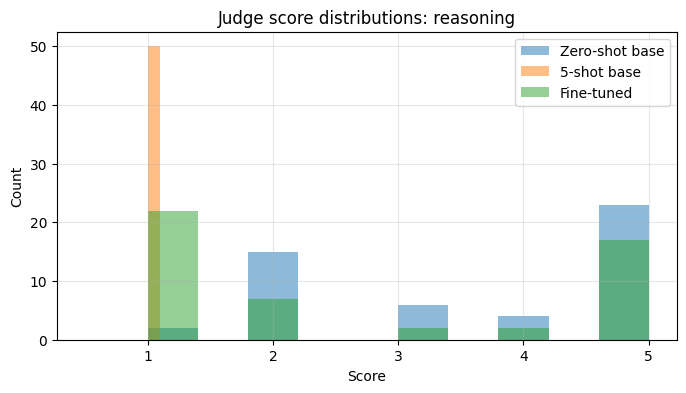

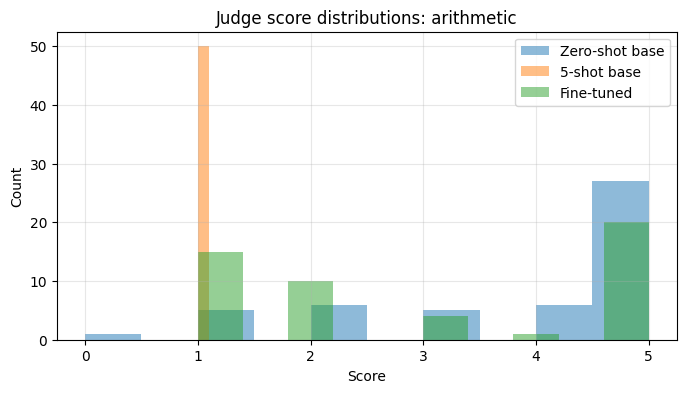

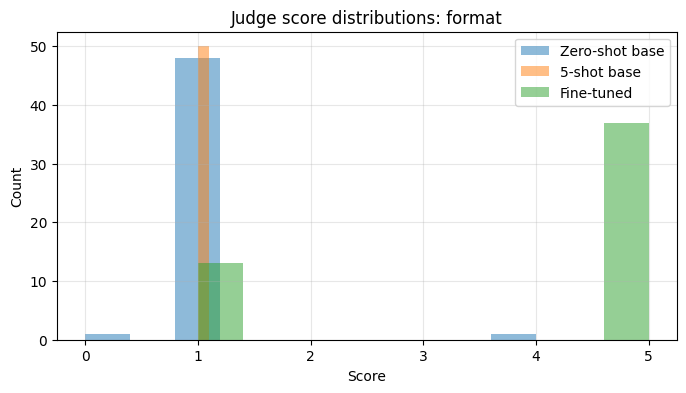

In [ ]:
for metric in ["reasoning", "arithmetic", "format"]:
    plt.figure(figsize=(8, 4))
    plt.hist(zero_shot_judge_frame[metric], alpha=0.5, label="Zero-shot base")
    plt.hist(few_shot_judge_frame[metric], alpha=0.5, label="5-shot base")
    plt.hist(finetuned_judge_frame[metric], alpha=0.5, label="Fine-tuned")
    plt.title(f"Judge score distributions: {metric}")
    plt.xlabel("Score")
    plt.ylabel("Count")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


### Task 7.2 Interpretation

The LLM-judge results tell the same overall story as exact-match accuracy. Exact match ranks the zero-shot base first (0.50), the fine-tuned model second (0.42), and the 5-shot base last (0.02); reasoning and arithmetic scores preserve that order at 3.62/3.82, 2.70/3.02, and 1.00/1.00, respectively. Arithmetic is slightly stronger than reasoning for both the zero-shot and fine-tuned models, but fine-tuning improves neither dimension over the zero-shot base.

The clearest change is format compliance: the fine-tuned model scores 3.96 ± 1.77, compared with 1.04 ± 0.45 for zero-shot. In this run, fine-tuning did not improve exact match over zero-shot, so the question's hypothetical condition is not actually observed. More generally, if exact match improved while reasoning did not, that would suggest the adapter learned answer patterns, domain cues, or the required final-answer format rather than a more reliable reasoning process; the current strong format score and weaker reasoning score point in that same direction.


## Task 7.3 - Bias Detection

Run 20 pairwise comparisons, then swap A and B and measure how often the judge changes its choice.


In [ ]:
pairwise_rows = []
for idx in range(20):
    question = zero_shot_judge_rows[idx]["question"]
    response_a = zero_shot_judge_rows[idx]["response"]
    response_b = finetuned_judge_rows[idx]["response"]
    original = judge_pairwise(
        api_key=OPENROUTER_API_KEY,
        model_name=LITELLM_JUDGE_MODEL,
        question=question,
        response_a=response_a,
        response_b=response_b,
    )
    flipped = judge_pairwise(
        api_key=OPENROUTER_API_KEY,
        model_name=LITELLM_JUDGE_MODEL,
        question=question,
        response_a=response_b,
        response_b=response_a,
    )
    pairwise_rows.append({
        "index": idx,
        "original_winner": original["winner"],
        "flipped_winner": flipped["winner"],
        "flip_changed": original["winner"] == flipped["winner"],
    })

pairwise_frame = pd.DataFrame(pairwise_rows)
flip_rate = float(np.mean(pairwise_frame["flip_changed"]))
print({"flip_rate": flip_rate})
pairwise_frame


{'flip_rate': 0.3}


,index,original_winner,flipped_winner,flip_changed
0,0,A,B,False
1,1,A,B,False
2,2,A,B,False
3,3,A,A,True
4,4,A,A,True
5,5,A,B,False
6,6,A,B,False
7,7,A,A,True
8,8,A,B,False
9,9,B,A,False


### Task 7.3 Interpretation

The flip rate is 0.30: in 6 of 20 comparisons, the judge changed which response it preferred solely because A and B were reordered. Because 30% exceeds the 20% threshold, the pairwise judge has substantial position bias and its individual verdicts deserve low confidence. Pairwise wins should therefore receive limited weight and be treated as noisy supporting evidence, not as a decisive model ranking. A more reliable evaluation would randomize order, score both orientations, aggregate only order-consistent verdicts, and corroborate them with exact match, rubric scores, and human review.
